# PowerCo Customer Churn Analysis

**Business question:** How do customer characteristics, pricing patterns and contract lifecycle relate to churn, and how well can a Random Forest identify customers who leave?

This notebook integrates the updated Task 2-4 materials into one analysis. Task 2 was supplied as a revision based on answers; Tasks 3 and 4 were supplied as model-answer notebooks from the BCG X / Forage simulation. Their feature-engineering and modeling approach is retained and attributed here.

## Contents
0. Environment and data inputs
1. Data understanding and descriptive statistics
2. Exploratory analysis
3. Feature engineering and preprocessing
4. Train/test split and Random Forest training
5. Classification evaluation
6. Feature importance and interpretation
7. Prediction export and summary


## Part 0: Environment and data inputs

Use the authorized simulation datasets in the local `data` folder. Raw customer and pricing files support exploration; the supplied `clean_data_after_eda.csv` provides the prepared customer table used by Task 3, including its existing annual and six-month pricing variables.

The model in Part 4 uses the feature table created in Part 3 directly. It does not reload the older `data_for_predictions.csv` file, whose date calculations and dummy-column naming differ from the updated Task 3.


In [1]:
from pathlib import Path
from datetime import datetime
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython import get_ipython
from sklearn import metrics
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier

warnings.filterwarnings("ignore", category=FutureWarning)
sns.set(color_codes=True)
if get_ipython() is not None:
    get_ipython().run_line_magic("matplotlib", "inline")
PROJECT_ROOT=Path.cwd().resolve()
if PROJECT_ROOT.name=="notebooks":
    PROJECT_ROOT=PROJECT_ROOT.parent
DATA_DIR=PROJECT_ROOT/"data"
CLIENT_PATH=DATA_DIR/"client_data.csv"
PRICE_PATH=DATA_DIR/"price_data.csv"
CLEAN_PATH=DATA_DIR/"clean_data_after_eda.csv"
RANDOM_STATE=42
EXPORT_PREDICTIONS=False
for path in [CLIENT_PATH,PRICE_PATH,CLEAN_PATH]:
    if not path.exists():
        raise FileNotFoundError(f"Required authorized input is missing: {path.name}")


## Part 1: Data understanding and descriptive statistics

The customer table contains one row per customer and a binary churn outcome. The pricing table has repeated observations by customer and date. Inspect their different observation units and numerical distributions before aggregation.


In [2]:
client_df=pd.read_csv(CLIENT_PATH)
price_df=pd.read_csv(PRICE_PATH)
pd.DataFrame({"dataset":["customers","prices"],"rows":[len(client_df),len(price_df)],"columns":[client_df.shape[1],price_df.shape[1]]})


     dataset    rows  columns
0  customers   14606       26
1     prices  193002        8

In [3]:
client_df.info()
price_df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 14606 entries, 0 to 14605
Data columns (total 26 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   id                              14606 non-null  object 
 1   channel_sales                   14606 non-null  object 
 2   cons_12m                        14606 non-null  int64  
 3   cons_gas_12m                    14606 non-null  int64  
 4   cons_last_month                 14606 non-null  int64  
 5   date_activ                      14606 non-null  object 
 6   date_end                        14606 non-null  object 
 7   date_modif_prod                 14606 non-null  object 
 8   date_renewal                    14606 non-null  object 
 9   forecast_cons_12m               14606 non-null  float64
 10  forecast_cons_year              14606 non-null  int64  
 11  forecast_discount_energy        14606 non-null  float64
 12  forecast_meter_rent_12m         

In [4]:
assert client_df["id"].is_unique
assert client_df["churn"].isin([0,1]).all()
pd.DataFrame({"customer_missing":client_df.isna().sum(),"price_missing":price_df.isna().sum()}).fillna(0).astype(int)


                                customer_missing  price_missing
channel_sales                                  0              0
churn                                          0              0
cons_12m                                       0              0
cons_gas_12m                                   0              0
cons_last_month                                0              0
date_activ                                     0              0
date_end                                       0              0
date_modif_prod                                0              0
date_renewal                                   0              0
forecast_cons_12m                              0              0
forecast_cons_year                             0              0
forecast_discount_energy                       0              0
forecast_meter_rent_12m                        0              0
forecast_price_energy_off_peak                 0              0
forecast_price_energy_peak              

In [5]:
client_df.describe()


           cons_12m  cons_gas_12m  cons_last_month  forecast_cons_12m  \
count  1.460600e+04  1.460600e+04     14606.000000       14606.000000   
mean   1.592203e+05  2.809238e+04     16090.269752        1868.614880   
std    5.734653e+05  1.629731e+05     64364.196422        2387.571531   
min    0.000000e+00  0.000000e+00         0.000000           0.000000   
25%    5.674750e+03  0.000000e+00         0.000000         494.995000   
50%    1.411550e+04  0.000000e+00       792.500000        1112.875000   
75%    4.076375e+04  0.000000e+00      3383.000000        2401.790000   
max    6.207104e+06  4.154590e+06    771203.000000       82902.830000   

       forecast_cons_year  forecast_discount_energy  forecast_meter_rent_12m  \
count        14606.000000              14606.000000             14606.000000   
mean          1399.762906                  0.966726                63.086871   
std           3247.786255                  5.108289                66.165783   
min              0.000

In [6]:
price_df.describe()


       price_off_peak_var  price_peak_var  price_mid_peak_var  \
count       193002.000000   193002.000000       193002.000000   
mean             0.141027        0.054630            0.030496   
std              0.025032        0.049924            0.036298   
min              0.000000        0.000000            0.000000   
25%              0.125976        0.000000            0.000000   
50%              0.146033        0.085483            0.000000   
75%              0.151635        0.101673            0.072558   
max              0.280700        0.229788            0.114102   

       price_off_peak_fix  price_peak_fix  price_mid_peak_fix  
count       193002.000000   193002.000000       193002.000000  
mean            43.334477       10.622875            6.409984  
std              5.410297       12.841895            7.773592  
min              0.000000        0.000000            0.000000  
25%             40.728885        0.000000            0.000000  
50%             44.266930     

## Part 2: Exploratory analysis

Describe the churn distribution, compare churn shares across categories, and inspect numerical distributions and outliers. These are descriptive comparisons rather than causal effects.


In [7]:
def plot_stacked_bars(dataframe, title_, size_=(18, 10), rot_=0, legend_='upper right'):
    ax = dataframe.plot(kind='bar', stacked=True, figsize=size_, rot=rot_, title=title_)
    annotate_stacked_bars(ax, textsize=14)
    plt.legend(['Retention', 'Churn'], loc=legend_)
    plt.ylabel('Company Base (%)')
    plt.show()

def annotate_stacked_bars(ax, pad=0.99, color='white', textsize=13):
    for p in ax.patches:
        value = str(round(p.get_height(), 1))
        if value == '0.0':
            continue
        ax.annotate(value, ((p.get_x() + p.get_width() / 2) * pad - 0.05, (p.get_y() + p.get_height() / 2) * pad), color=color, size=textsize)

def plot_distribution(dataframe, column, ax, bins_=50):
    temp = pd.DataFrame({'Retention': dataframe[dataframe['churn'] == 0][column], 'Churn': dataframe[dataframe['churn'] == 1][column]})
    temp[['Retention', 'Churn']].plot(kind='hist', bins=bins_, ax=ax, stacked=True)
    ax.set_xlabel(column)
    ax.ticklabel_format(style='plain', axis='x')


### Churn distribution


In [8]:
churn = client_df[['id', 'churn']]
churn_total = churn.groupby(churn['churn']).count()
churn_percentage = churn_total / churn_total.sum() * 100


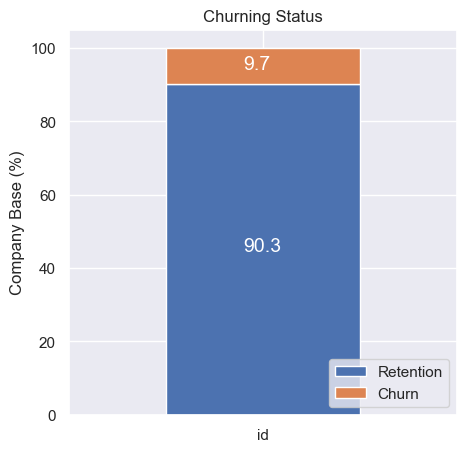

In [9]:
plot_stacked_bars(churn_percentage.transpose(), 'Churning Status', (5, 5), legend_='lower right')


### Sales channel


In [10]:
channel = client_df[['id', 'channel_sales', 'churn']]
channel = channel.groupby(['channel_sales', 'churn'])['id'].count().unstack(level=1).fillna(0)
channel_churn = (channel.div(channel.sum(axis=1), axis=0) * 100).sort_values(by=[1], ascending=False)


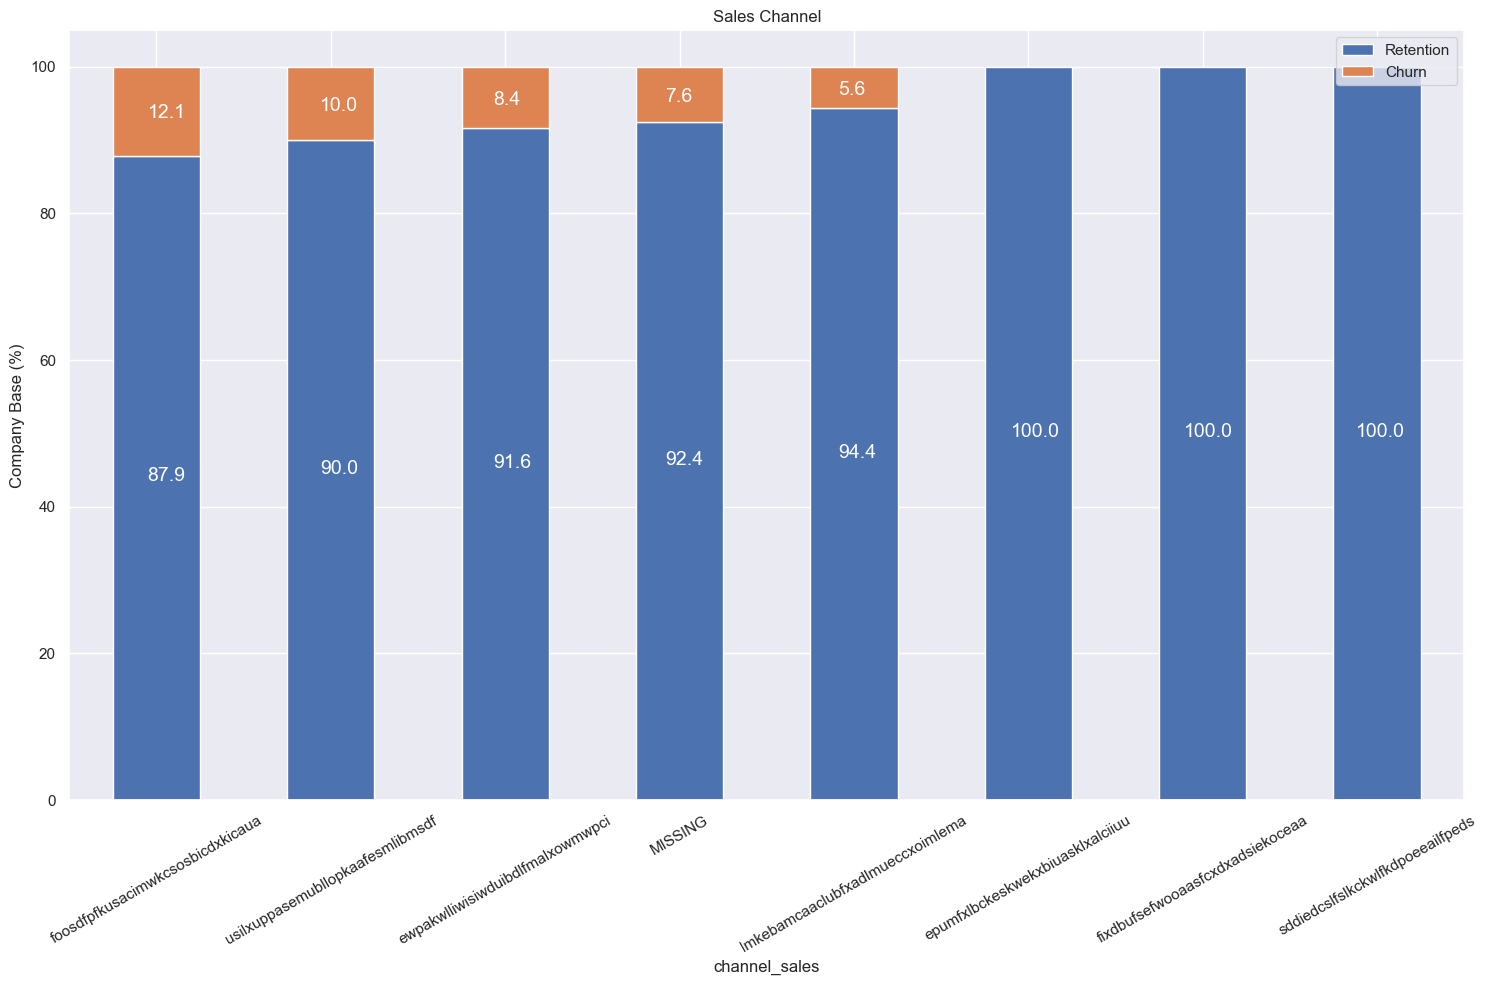

In [11]:
plot_stacked_bars(channel_churn, 'Sales Channel', rot_=30)


### Gas contract and active products


In [12]:
contract_type = client_df[['id', 'has_gas', 'churn']]
contract_type = contract_type.groupby(['has_gas', 'churn'])['id'].count().unstack(level=1).fillna(0)
contract_type_churn = (contract_type.div(contract_type.sum(axis=1), axis=0) * 100).sort_values(by=[1], ascending=False)


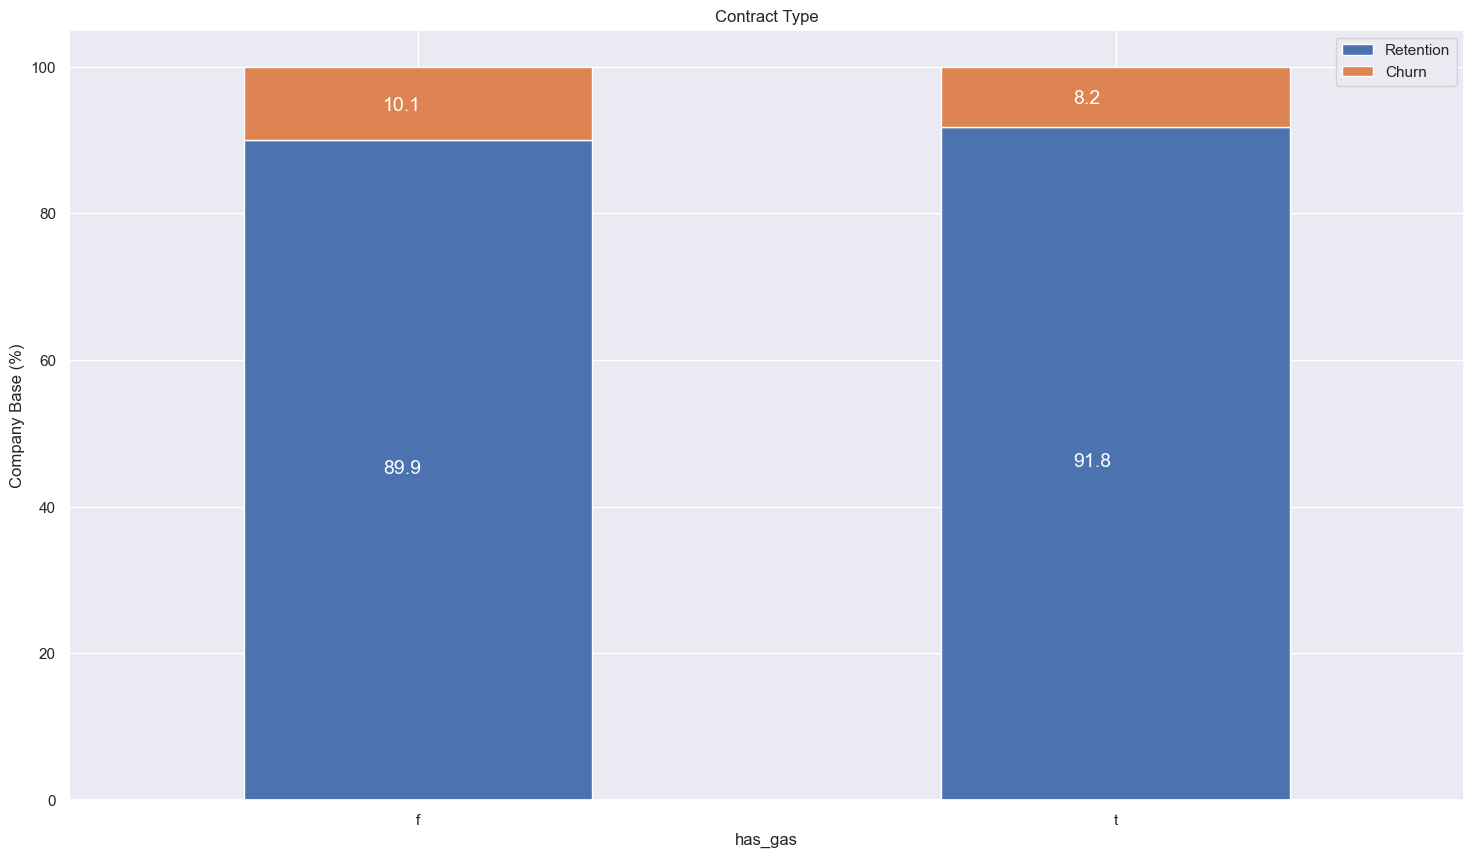

In [13]:
plot_stacked_bars(contract_type_churn, 'Contract Type')


In [14]:
Active = client_df[['id', 'nb_prod_act', 'churn']]
Active = Active.groupby(['nb_prod_act', 'churn'])['id'].count().unstack(level=1).fillna(0)
Active_products_churn = (Active.div(Active.sum(axis=1), axis=0) * 100).sort_values(by=[1], ascending=False)


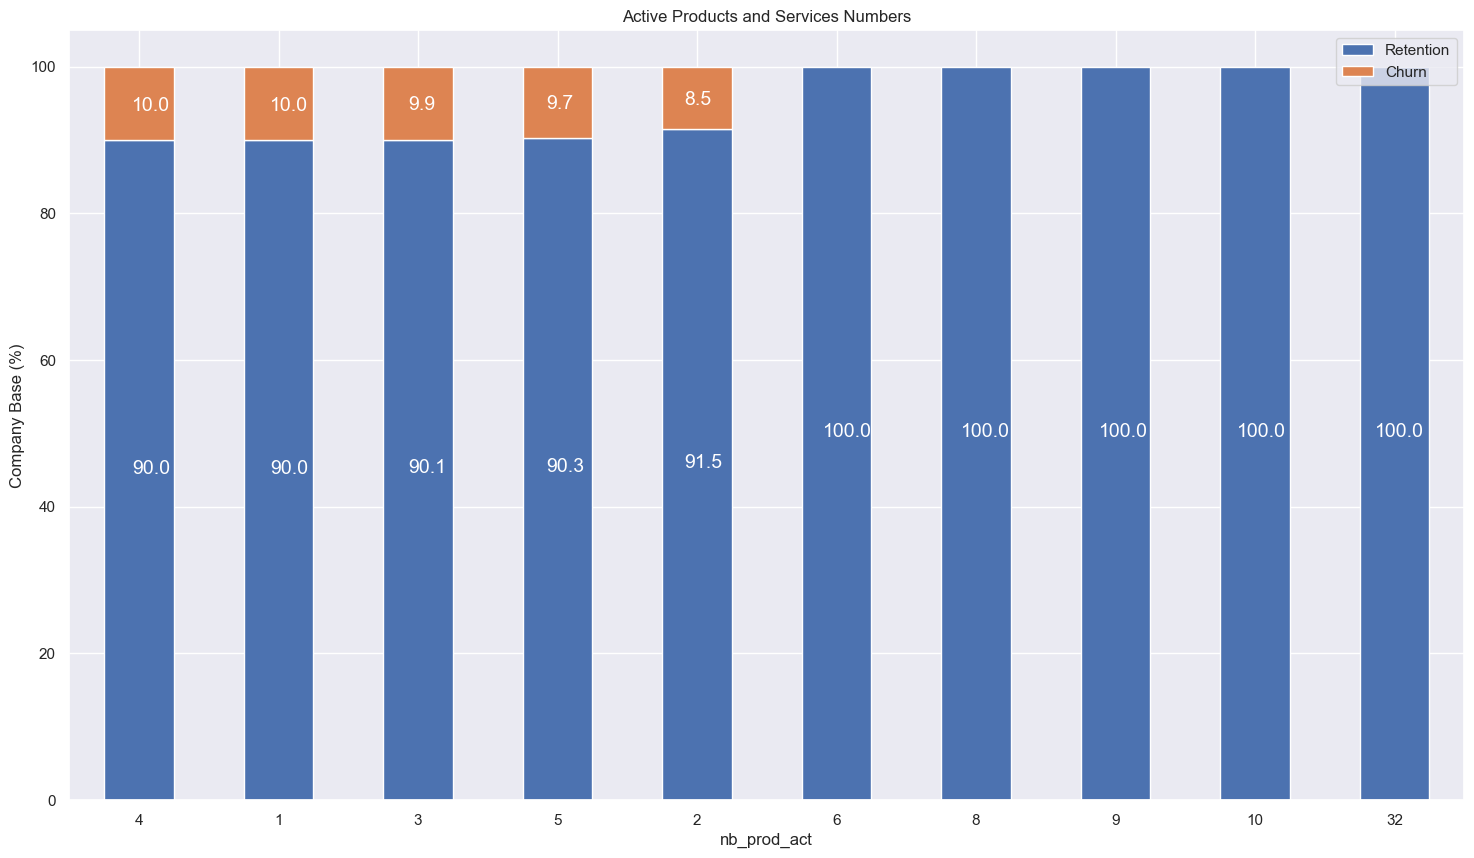

In [15]:
plot_stacked_bars(Active_products_churn, 'Active Products and Services Numbers')


### Consumption and forecast distributions


In [16]:
consumption = client_df[['id', 'cons_12m', 'cons_gas_12m', 'cons_last_month', 'imp_cons', 'has_gas', 'churn']]


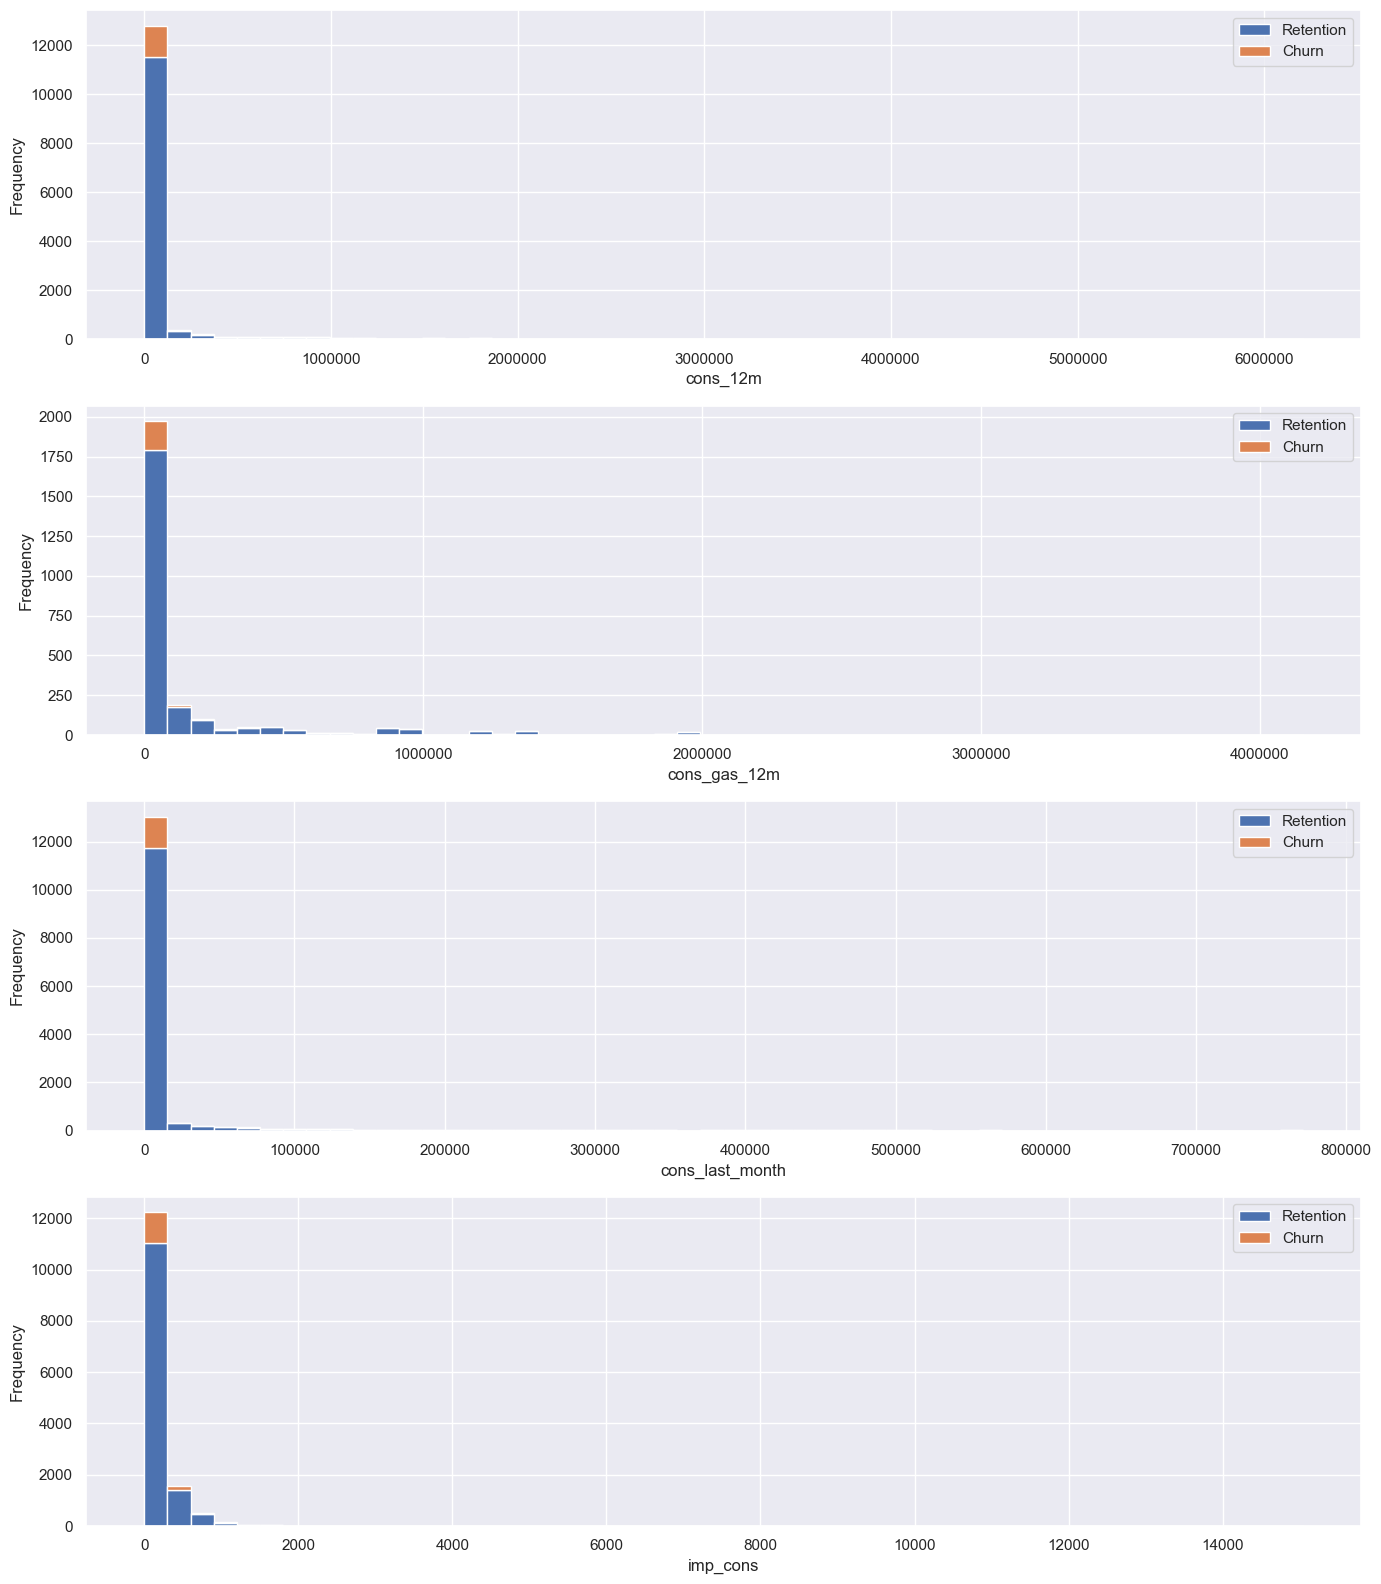

In [17]:
fig, axs = plt.subplots(nrows=4, figsize=(14, 16))
plot_distribution(consumption, 'cons_12m', axs[0])
plot_distribution(consumption[consumption['has_gas'] == 't'], 'cons_gas_12m', axs[1])
plot_distribution(consumption, 'cons_last_month', axs[2])
plot_distribution(consumption, 'imp_cons', axs[3])
plt.tight_layout()
plt.show()


In [18]:
forecast = client_df[['id', 'forecast_cons_12m', 'forecast_cons_year', 'forecast_discount_energy', 'forecast_meter_rent_12m', 'forecast_price_energy_off_peak', 'forecast_price_energy_peak', 'forecast_price_pow_off_peak', 'churn']]


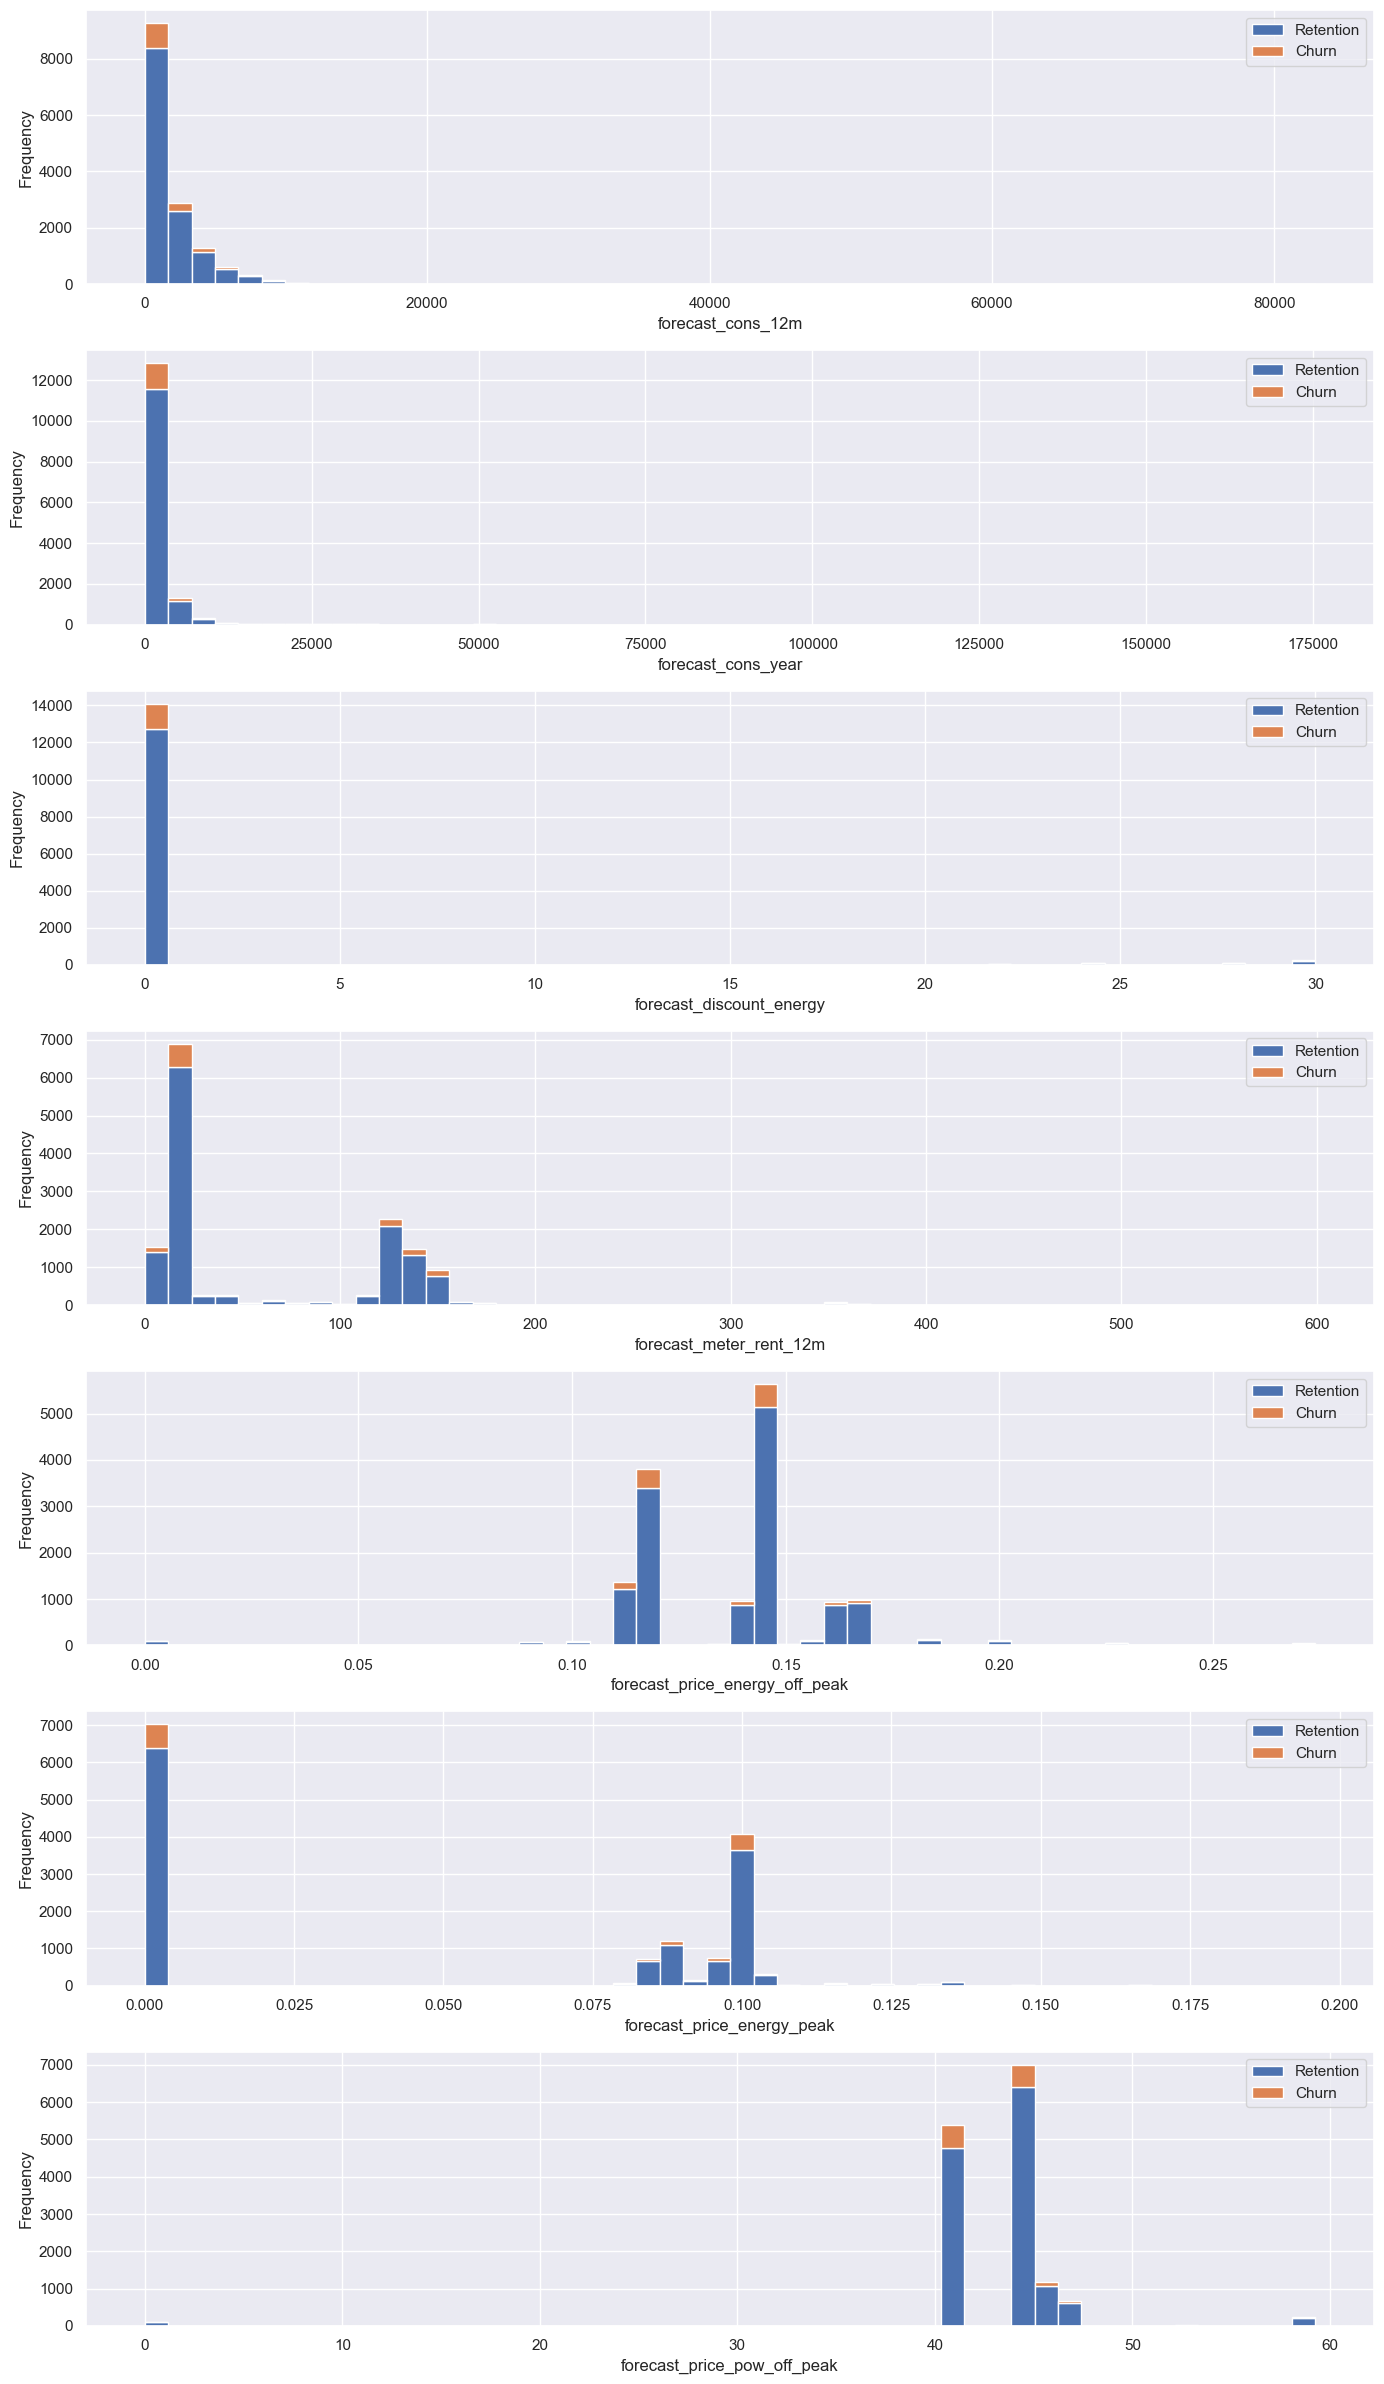

In [19]:
fig, axs = plt.subplots(nrows=7, figsize=(14, 24))
plot_distribution(client_df, 'forecast_cons_12m', axs[0])
plot_distribution(client_df, 'forecast_cons_year', axs[1])
plot_distribution(client_df, 'forecast_discount_energy', axs[2])
plot_distribution(client_df, 'forecast_meter_rent_12m', axs[3])
plot_distribution(client_df, 'forecast_price_energy_off_peak', axs[4])
plot_distribution(client_df, 'forecast_price_energy_peak', axs[5])
plot_distribution(client_df, 'forecast_price_pow_off_peak', axs[6])
plt.tight_layout()
plt.show()


### Margin and subscribed-power distributions


In [20]:
margin = client_df[['id', 'margin_gross_pow_ele', 'margin_net_pow_ele', 'net_margin']]


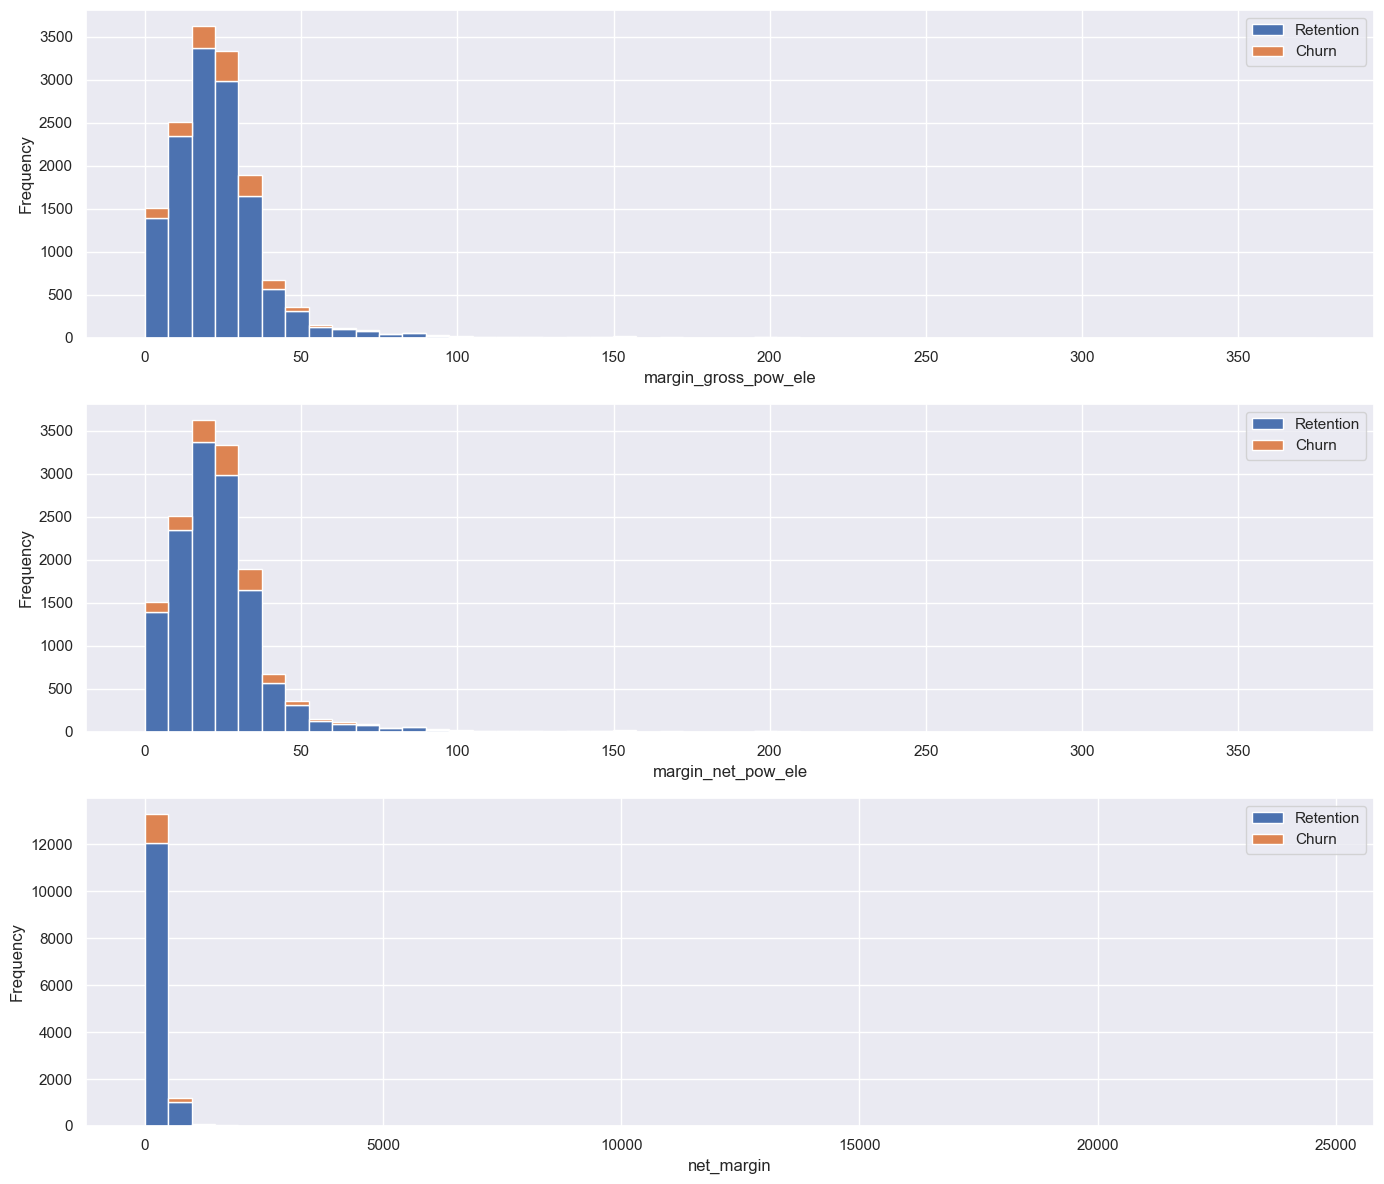

In [21]:
fig, axs = plt.subplots(nrows=3, figsize=(14, 12))
plot_distribution(client_df, 'margin_gross_pow_ele', axs[0])
plot_distribution(client_df, 'margin_net_pow_ele', axs[1])
plot_distribution(client_df, 'net_margin', axs[2])
plt.tight_layout()
plt.show()


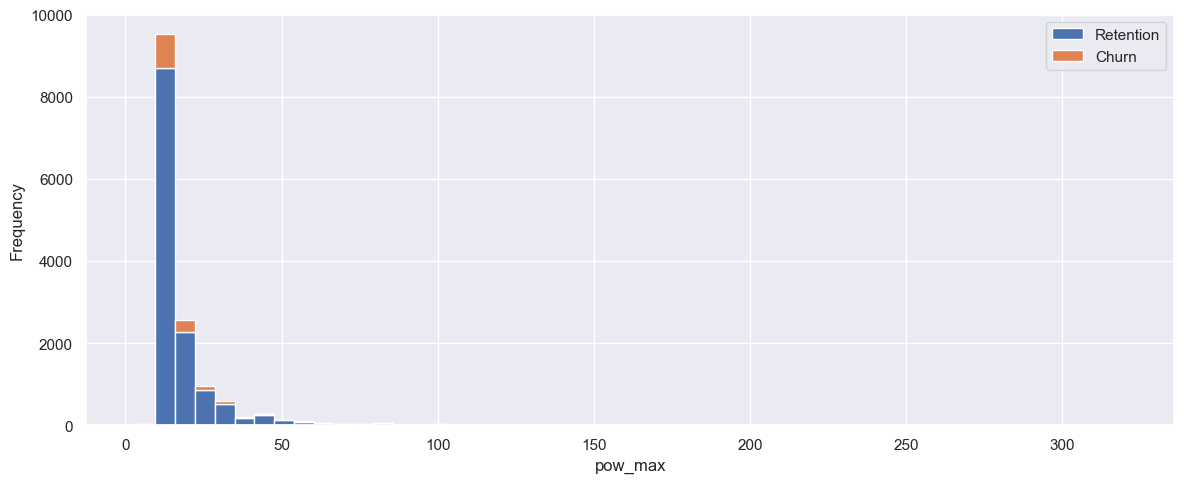

In [22]:
fig, axs = plt.subplots(nrows=1, figsize=(12, 5))
plot_distribution(client_df, 'pow_max', axs)
plt.tight_layout()
plt.show()


### Outlier and skewness inspection

Boxplots complement the histograms and identify long-tailed variables for the later transformation step.


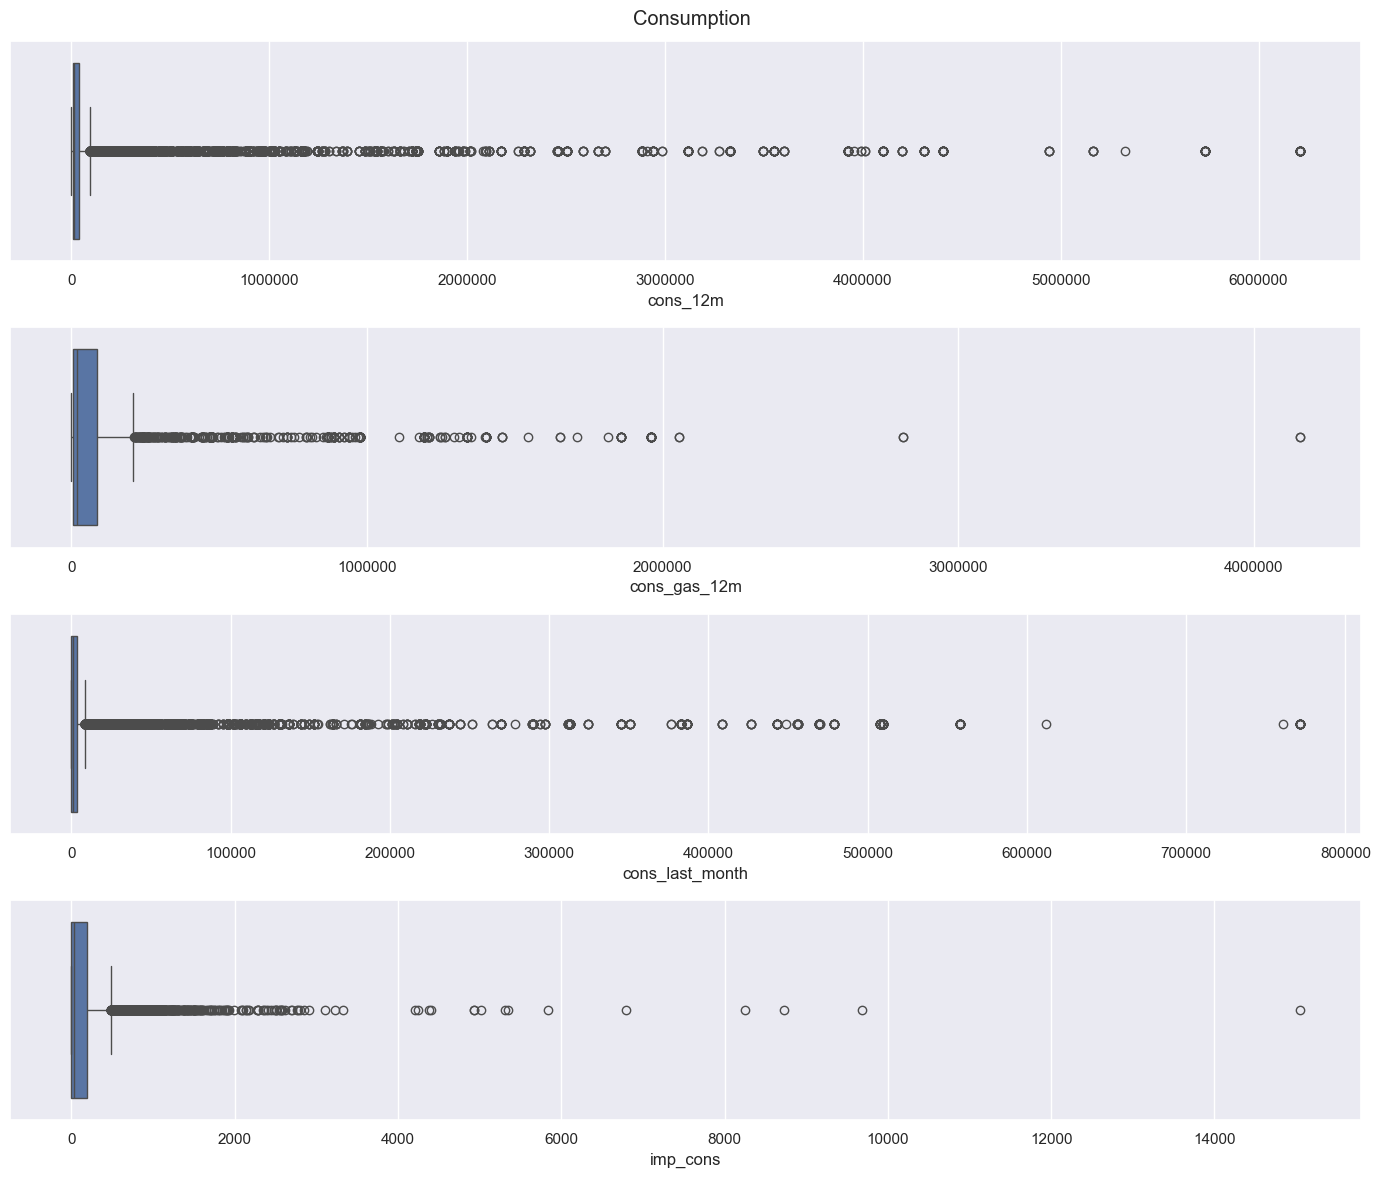

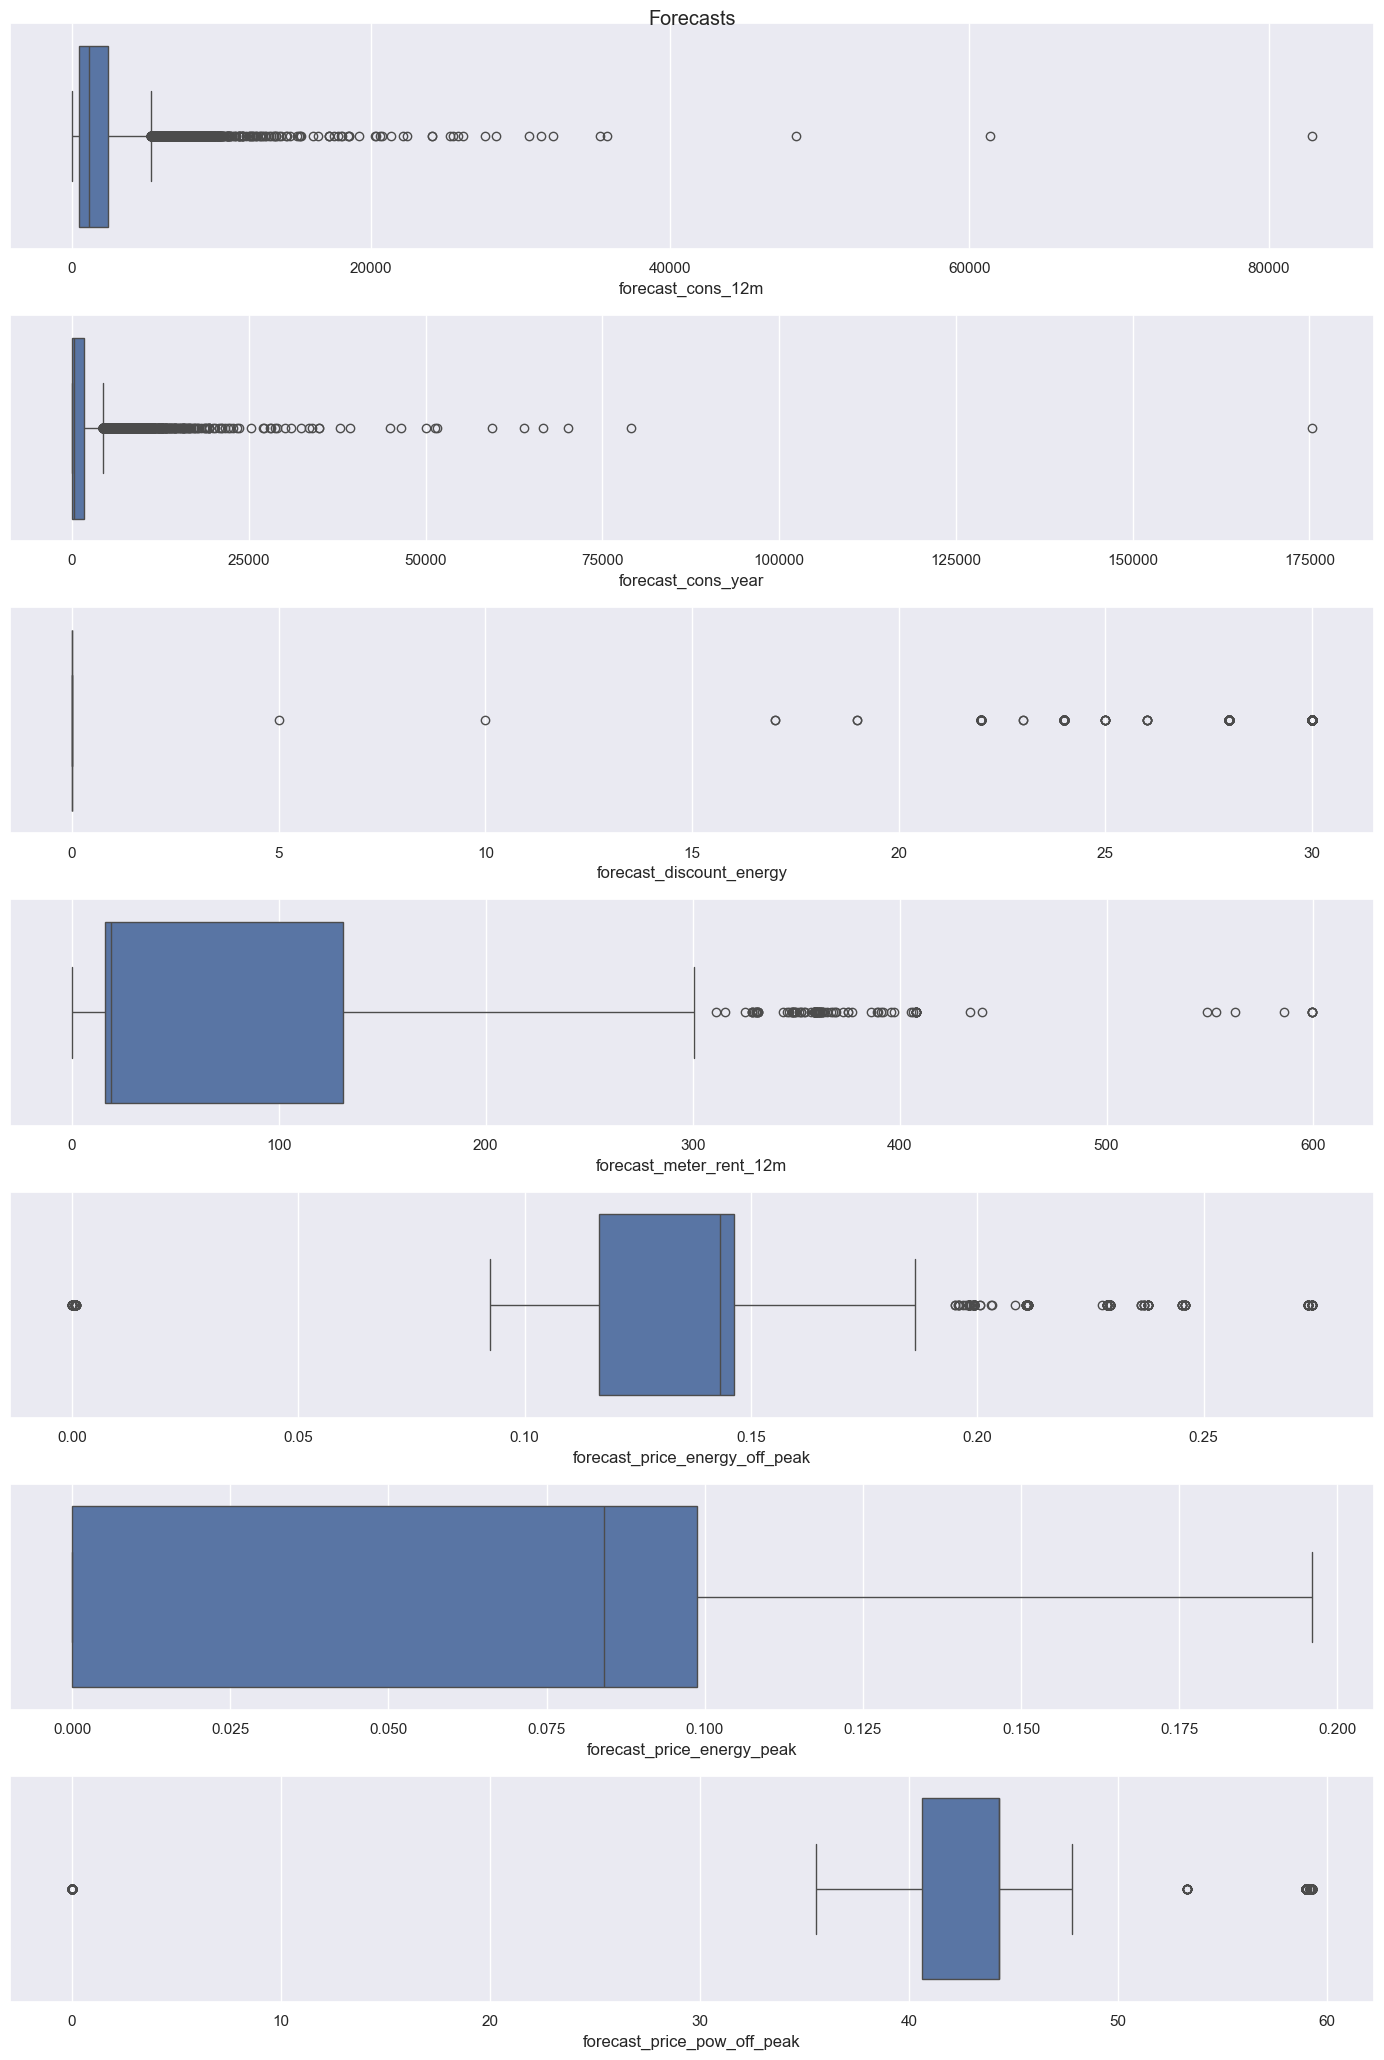

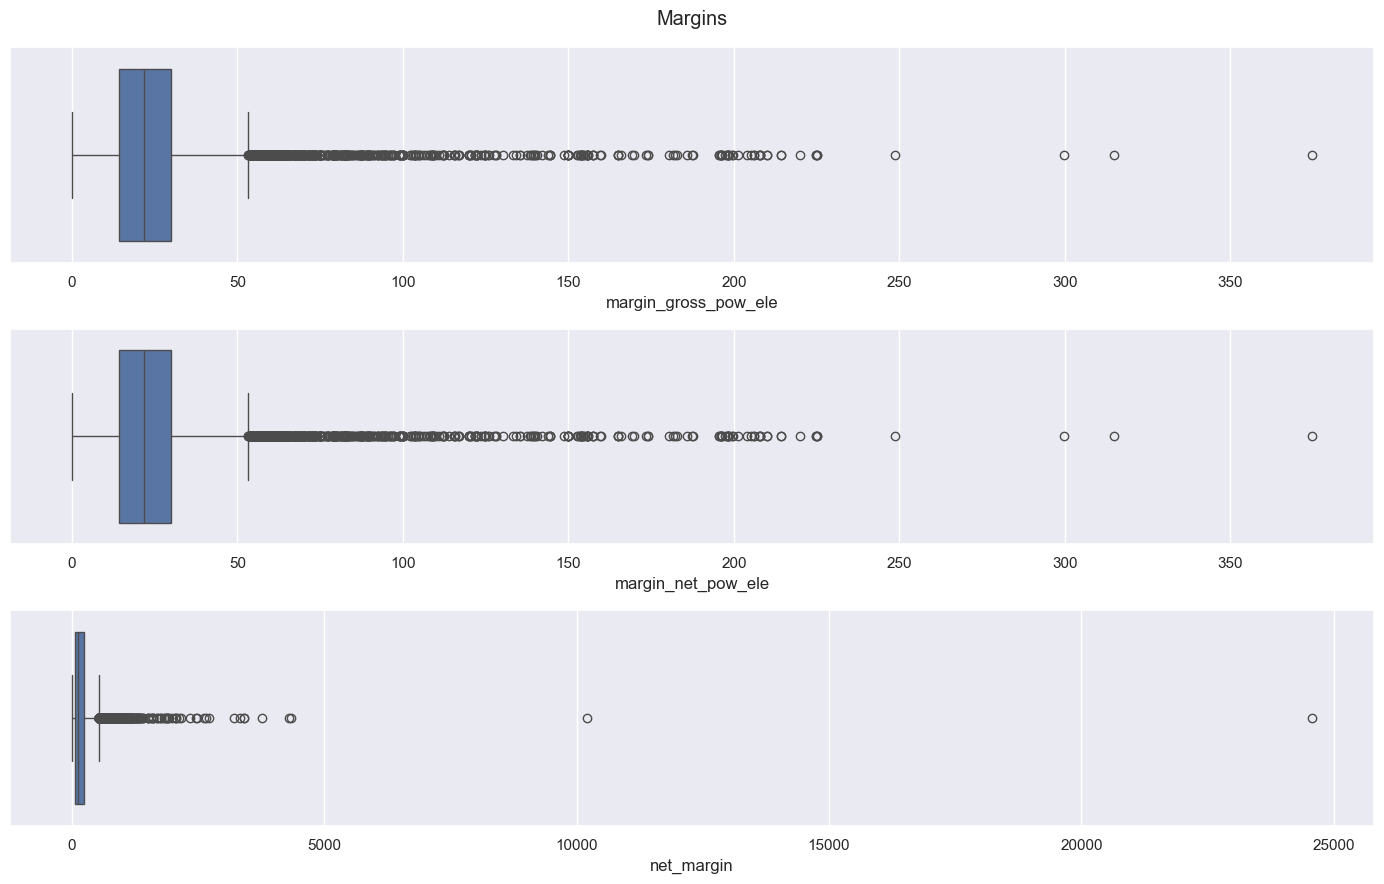

In [23]:
boxplot_groups={
    "Consumption":consumption[["cons_12m","cons_gas_12m","cons_last_month","imp_cons"]],
    "Forecasts":forecast.drop(columns=["id","churn"]),
    "Margins":margin.drop(columns="id"),
}
for group,values in boxplot_groups.items():
    fig,axes=plt.subplots(len(values.columns),1,figsize=(14,3*len(values.columns)))
    axes=np.atleast_1d(axes)
    for ax,column in zip(axes,values.columns):
        series=values[column]
        if column=="cons_gas_12m":
            series=consumption.loc[consumption.has_gas.eq("t"),column]
        sns.boxplot(x=series,ax=ax)
        ax.ticklabel_format(style="plain",axis="x")
    fig.suptitle(group)
    plt.tight_layout()
    plt.show()


## Part 3: Feature engineering and preprocessing

The following transformations follow the supplied Task 3 model-answer workflow. Begin from its prepared customer table, then construct pricing, contract-lifecycle and encoded categorical features. The earlier prepared pricing variables are inputs, rather than claimed as newly constructed by the code below.


In [24]:
df=pd.read_csv(CLEAN_PATH)
for column in ["date_activ","date_end","date_modif_prod","date_renewal"]:
    df[column]=pd.to_datetime(df[column],format="%Y-%m-%d")
price_df["price_date"]=pd.to_datetime(price_df["price_date"],format="%Y-%m-%d")


### First-to-last off-peak price difference

Aggregate prices by customer and month, then calculate the last-minus-first observed off-peak differences. In the simulation period this represents December versus January when both months are available.


In [25]:
monthly_price_by_id = price_df.groupby(['id', 'price_date']).agg({'price_off_peak_var': 'mean', 'price_off_peak_fix': 'mean'}).reset_index()
jan_prices = monthly_price_by_id.groupby('id').first().reset_index()
dec_prices = monthly_price_by_id.groupby('id').last().reset_index()
diff = pd.merge(dec_prices.rename(columns={'price_off_peak_var': 'dec_1', 'price_off_peak_fix': 'dec_2'}), jan_prices.drop(columns='price_date'), on='id')
diff['offpeak_diff_dec_january_energy'] = diff['dec_1'] - diff['price_off_peak_var']
diff['offpeak_diff_dec_january_power'] = diff['dec_2'] - diff['price_off_peak_fix']
diff = diff[['id', 'offpeak_diff_dec_january_energy', 'offpeak_diff_dec_january_power']]


In [26]:
df = pd.merge(df, diff, on='id')


### Mean differences between tariff periods

Construct differences among off-peak, peak and mid-peak mean prices for variable and fixed price components. These features compare tariff periods, not consecutive calendar months.


In [27]:
mean_prices = price_df.groupby(['id']).agg({'price_off_peak_var': 'mean', 'price_peak_var': 'mean', 'price_mid_peak_var': 'mean', 'price_off_peak_fix': 'mean', 'price_peak_fix': 'mean', 'price_mid_peak_fix': 'mean'}).reset_index()


In [28]:
mean_prices['off_peak_peak_var_mean_diff'] = mean_prices['price_off_peak_var'] - mean_prices['price_peak_var']
mean_prices['peak_mid_peak_var_mean_diff'] = mean_prices['price_peak_var'] - mean_prices['price_mid_peak_var']
mean_prices['off_peak_mid_peak_var_mean_diff'] = mean_prices['price_off_peak_var'] - mean_prices['price_mid_peak_var']
mean_prices['off_peak_peak_fix_mean_diff'] = mean_prices['price_off_peak_fix'] - mean_prices['price_peak_fix']
mean_prices['peak_mid_peak_fix_mean_diff'] = mean_prices['price_peak_fix'] - mean_prices['price_mid_peak_fix']
mean_prices['off_peak_mid_peak_fix_mean_diff'] = mean_prices['price_off_peak_fix'] - mean_prices['price_mid_peak_fix']


In [29]:
columns = ['id', 'off_peak_peak_var_mean_diff', 'peak_mid_peak_var_mean_diff', 'off_peak_mid_peak_var_mean_diff', 'off_peak_peak_fix_mean_diff', 'peak_mid_peak_fix_mean_diff', 'off_peak_mid_peak_fix_mean_diff']
df = pd.merge(df, mean_prices[columns], on='id')


### Maximum monthly tariff-period differences

Calculate the same within-month tariff-period differences and retain each customer's maximum observed difference over the historical months.


In [30]:
mean_prices_by_month = price_df.groupby(['id', 'price_date']).agg({'price_off_peak_var': 'mean', 'price_peak_var': 'mean', 'price_mid_peak_var': 'mean', 'price_off_peak_fix': 'mean', 'price_peak_fix': 'mean', 'price_mid_peak_fix': 'mean'}).reset_index()


In [31]:
mean_prices_by_month['off_peak_peak_var_mean_diff'] = mean_prices_by_month['price_off_peak_var'] - mean_prices_by_month['price_peak_var']
mean_prices_by_month['peak_mid_peak_var_mean_diff'] = mean_prices_by_month['price_peak_var'] - mean_prices_by_month['price_mid_peak_var']
mean_prices_by_month['off_peak_mid_peak_var_mean_diff'] = mean_prices_by_month['price_off_peak_var'] - mean_prices_by_month['price_mid_peak_var']
mean_prices_by_month['off_peak_peak_fix_mean_diff'] = mean_prices_by_month['price_off_peak_fix'] - mean_prices_by_month['price_peak_fix']
mean_prices_by_month['peak_mid_peak_fix_mean_diff'] = mean_prices_by_month['price_peak_fix'] - mean_prices_by_month['price_mid_peak_fix']
mean_prices_by_month['off_peak_mid_peak_fix_mean_diff'] = mean_prices_by_month['price_off_peak_fix'] - mean_prices_by_month['price_mid_peak_fix']


In [32]:
max_diff_across_periods_months = mean_prices_by_month.groupby(['id']).agg({'off_peak_peak_var_mean_diff': 'max', 'peak_mid_peak_var_mean_diff': 'max', 'off_peak_mid_peak_var_mean_diff': 'max', 'off_peak_peak_fix_mean_diff': 'max', 'peak_mid_peak_fix_mean_diff': 'max', 'off_peak_mid_peak_fix_mean_diff': 'max'}).reset_index().rename(columns={'off_peak_peak_var_mean_diff': 'off_peak_peak_var_max_monthly_diff', 'peak_mid_peak_var_mean_diff': 'peak_mid_peak_var_max_monthly_diff', 'off_peak_mid_peak_var_mean_diff': 'off_peak_mid_peak_var_max_monthly_diff', 'off_peak_peak_fix_mean_diff': 'off_peak_peak_fix_max_monthly_diff', 'peak_mid_peak_fix_mean_diff': 'peak_mid_peak_fix_max_monthly_diff', 'off_peak_mid_peak_fix_mean_diff': 'off_peak_mid_peak_fix_max_monthly_diff'})


In [33]:
columns = ['id', 'off_peak_peak_var_max_monthly_diff', 'peak_mid_peak_var_max_monthly_diff', 'off_peak_mid_peak_var_max_monthly_diff', 'off_peak_peak_fix_max_monthly_diff', 'peak_mid_peak_fix_max_monthly_diff', 'off_peak_mid_peak_fix_max_monthly_diff']
df = pd.merge(df, max_diff_across_periods_months[columns], on='id')


### Contract lifecycle

Measure tenure in whole years using the supplied contract-start/end definition. Calculate whole-month distances from January 1, 2016 to activation, contract end, product modification and renewal. Tenure here is measured in years, not months.


In [34]:
df['date_activ'] = pd.to_datetime(df['date_activ'])
df['date_end'] = pd.to_datetime(df['date_end'])
df['tenure'] = (df['date_end'] - df['date_activ']).dt.days // 365


In [35]:
df.groupby(['tenure']).agg({'churn': 'mean'}).sort_values(by='tenure', ascending=False)


           churn
tenure          
13      0.095238
12      0.083333
11      0.059783
10      0.045455
9       0.012500
8       0.047244
7       0.075472
6       0.075407
5       0.091999
4       0.127473
3       0.143874
2       0.176471

In [36]:
def convert_months(reference_date, df, column):
    """
    return number of whole months between two dates
    """
    dates = pd.to_datetime(df[column])
    year_diff = reference_date.year - dates.dt.year
    month_diff = reference_date.month - dates.dt.month
    months = year_diff * 12 + month_diff
    months -= (reference_date.day < dates.dt.day).astype(int)
    return months


In [37]:
reference_date = datetime(2016, 1, 1)
df['months_activ'] = convert_months(reference_date, df, 'date_activ')
df['months_to_end'] = -convert_months(reference_date, df, 'date_end')
df['months_modif_prod'] = convert_months(reference_date, df, 'date_modif_prod')
df['months_renewal'] = convert_months(reference_date, df, 'date_renewal')


In [38]:
remove = ['date_activ', 'date_end', 'date_modif_prod', 'date_renewal']
df = df.drop(columns=remove)


### Boolean and categorical encoding

Map the gas-contract indicator to 0/1. One-hot encode sales channel and origin, retaining categories observed at least 100 times in the prepared data.


In [39]:
df['has_gas'] = df['has_gas'].replace(['t', 'f'], [1, 0])
df.groupby(['has_gas']).agg({'churn': 'mean'})


            churn
has_gas          
0        0.100544
1        0.081856

In [40]:
cols = ['channel_sales', 'origin_up']
min_count = 100
value_counts = {col: df[col].value_counts() for col in cols}
df = pd.get_dummies(df, columns=cols, prefix=cols, dtype=int)
for col in cols:
    keep_cols = set(value_counts[col][value_counts[col] >= min_count].index.astype(str))
    dummy_cols = [c for c in df.columns if c.startswith(f'{col}_')]
    drop_cols = [c for c in dummy_cols if c.split(f'{col}_', 1)[1] not in keep_cols]
    df.drop(columns=drop_cols, inplace=True)


### Numerical transformation and correlation diagnostics

Apply the supplied log10(x+1) transformation to the listed nonnegative variables and inspect their distributions. Random Forest does not require normally distributed inputs; a reduced standard deviation alone is not evidence of better prediction.

Review correlations as a descriptive diagnostic and retain the source workflow's removal of `num_years_antig` and `forecast_cons_year`. The correlation display is not treated as a causal test.


In [41]:
skewed_cols = ['cons_12m', 'cons_gas_12m', 'cons_last_month', 'forecast_cons_12m', 'forecast_cons_year', 'forecast_discount_energy', 'forecast_meter_rent_12m', 'forecast_price_energy_off_peak', 'forecast_price_energy_peak', 'forecast_price_pow_off_peak']
print('Before log transform:')
print(df[skewed_cols].describe())
df[skewed_cols] = np.log10(df[skewed_cols] + 1)
print('After log transform:')
print(df[skewed_cols].describe())


Before log transform:
           cons_12m  cons_gas_12m  cons_last_month  forecast_cons_12m  \
count  1.460600e+04  1.460600e+04     14606.000000       14606.000000   
mean   1.592203e+05  2.809238e+04     16090.269752        1868.614880   
std    5.734653e+05  1.629731e+05     64364.196422        2387.571531   
min    0.000000e+00  0.000000e+00         0.000000           0.000000   
25%    5.674750e+03  0.000000e+00         0.000000         494.995000   
50%    1.411550e+04  0.000000e+00       792.500000        1112.875000   
75%    4.076375e+04  0.000000e+00      3383.000000        2401.790000   
max    6.207104e+06  4.154590e+06    771203.000000       82902.830000   

       forecast_cons_year  forecast_discount_energy  forecast_meter_rent_12m  \
count        14606.000000              14606.000000             14606.000000   
mean          1399.762906                  0.966726                63.086871   
std           3247.786255                  5.108289                66.165783   


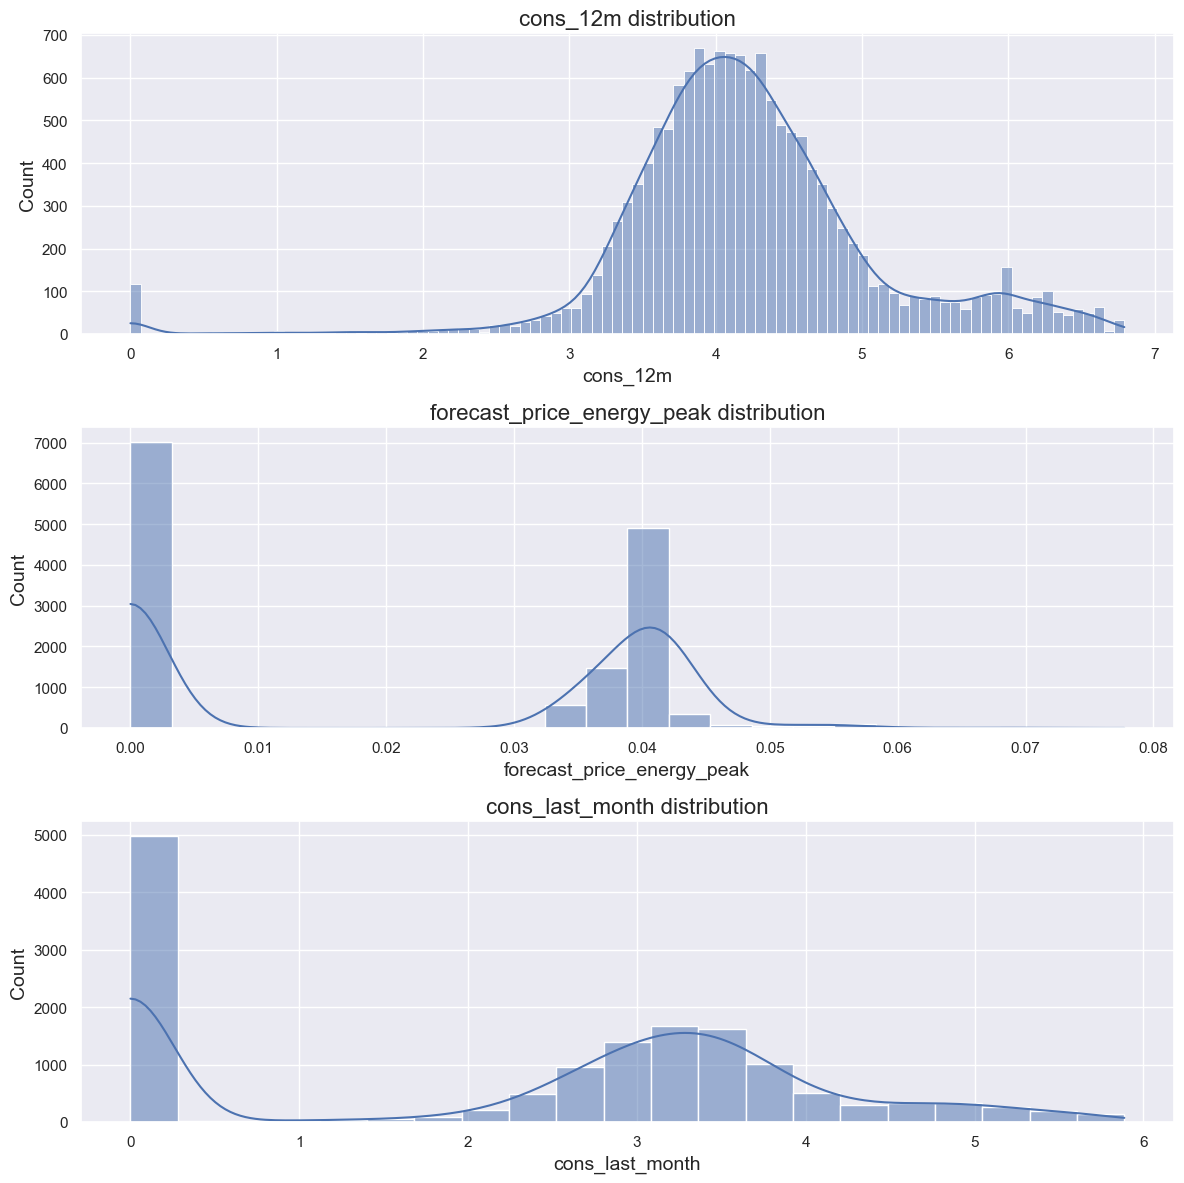

In [42]:
cols = ['cons_12m', 'forecast_price_energy_peak', 'cons_last_month']
fig, axs = plt.subplots(nrows=len(cols), figsize=(12, 12))
for ax, col in zip(axs, cols):
    sns.histplot(df[col].dropna(), kde=True, ax=ax)
    ax.set_title(f'{col} distribution', fontsize=16)
    ax.set_xlabel(col, fontsize=14)
    ax.set_ylabel('Count', fontsize=14)
plt.tight_layout()
plt.show()


In [43]:
correlation = df.drop(columns=['id']).corr()


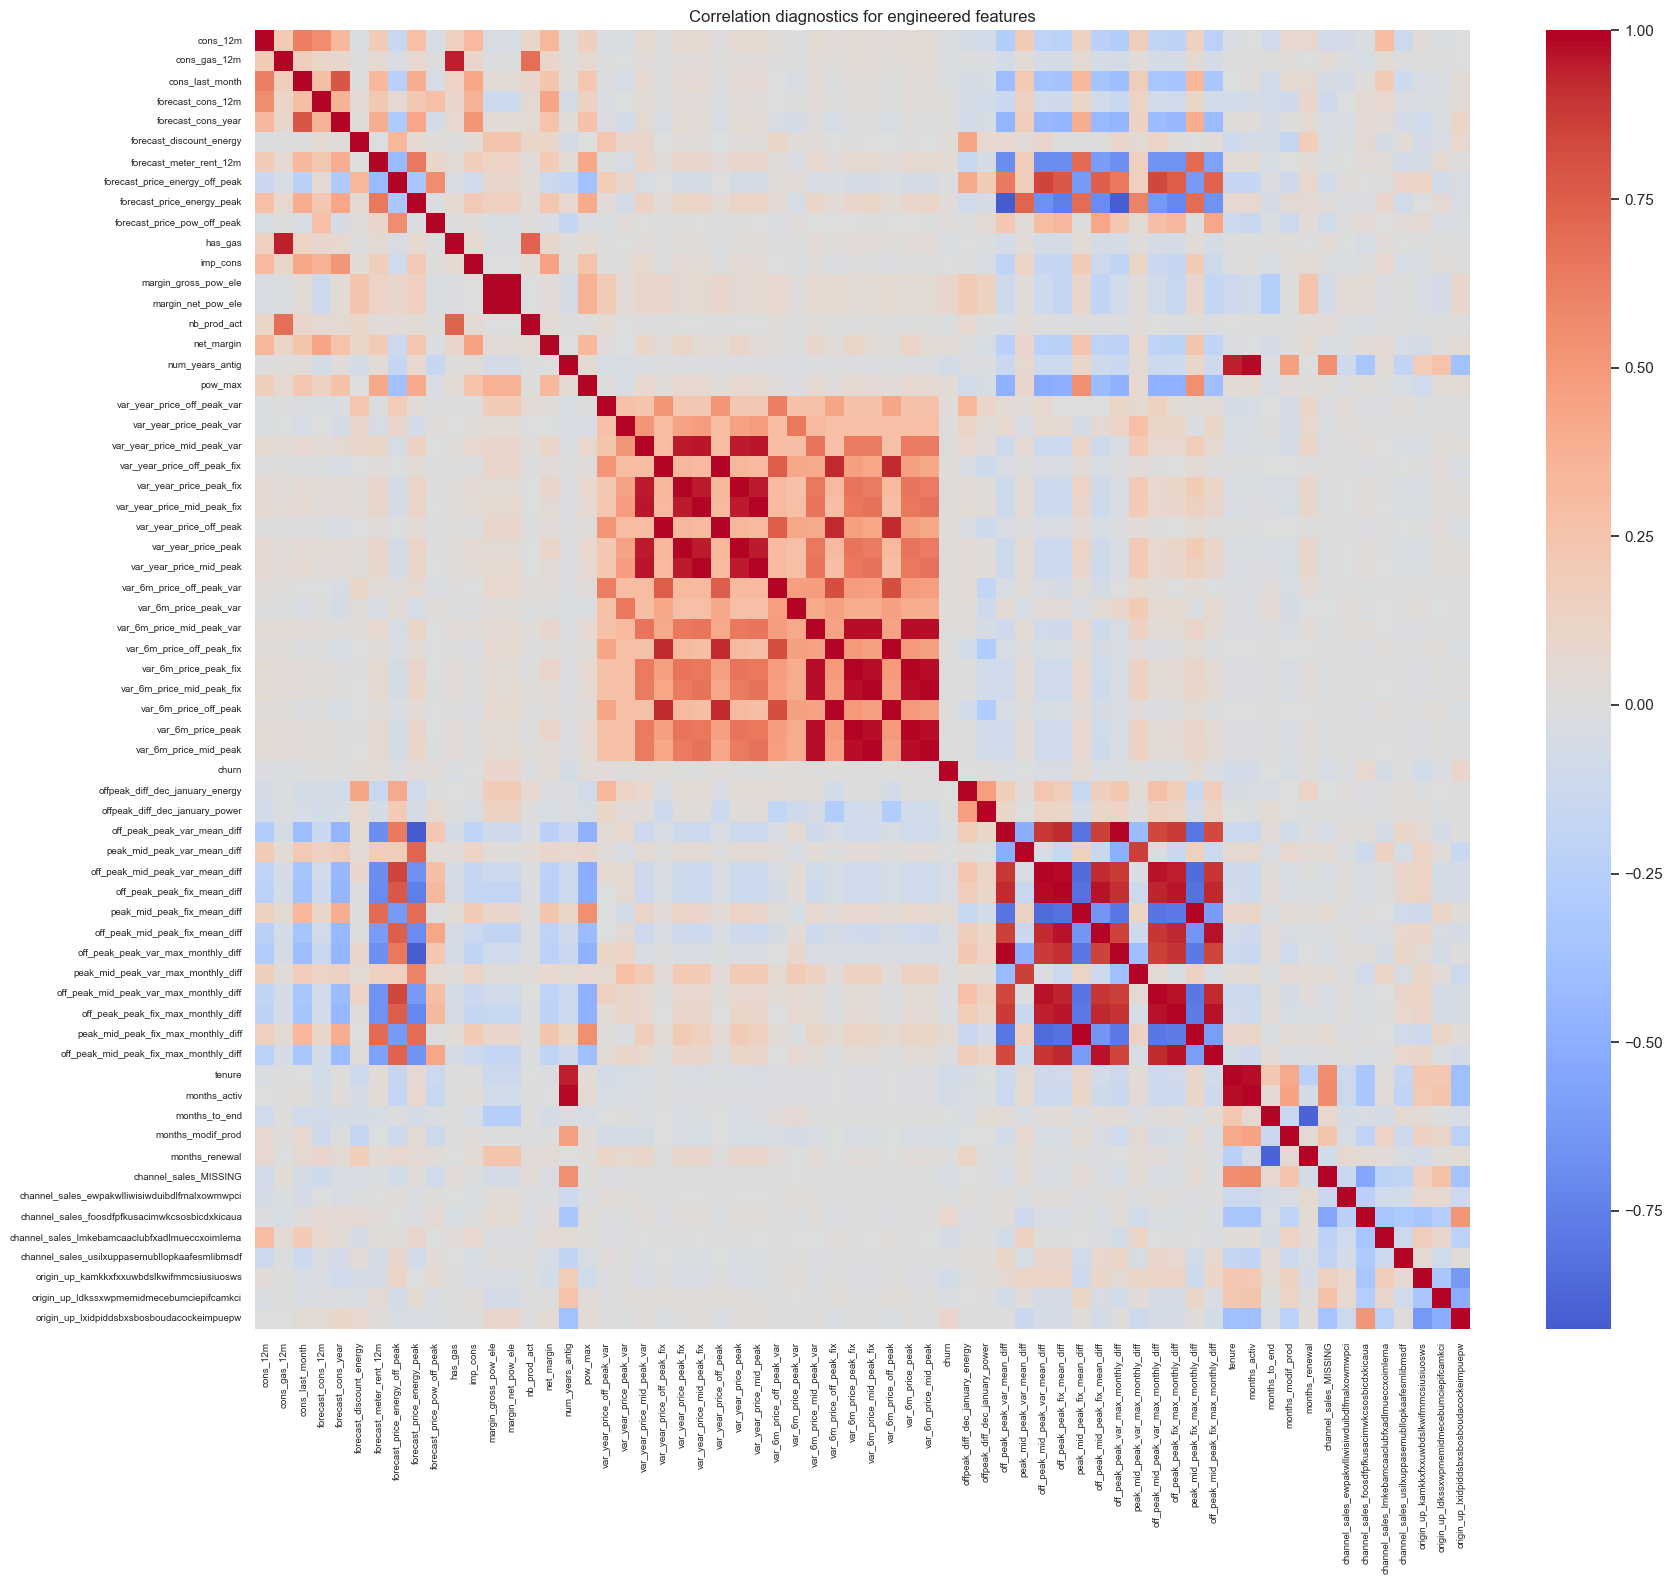

In [44]:
plt.figure(figsize=(18,16))
sns.heatmap(correlation,xticklabels=True,yticklabels=True,cmap="coolwarm",center=0,annot=False)
plt.xticks(fontsize=7)
plt.yticks(fontsize=7)
plt.title("Correlation diagnostics for engineered features")
plt.tight_layout()
plt.show()


In [45]:
df = df.drop(columns=['num_years_antig', 'forecast_cons_year'])


In [46]:
model_df=df.copy()
X=model_df.drop(columns=["id","churn"])
y=model_df["churn"].astype(int)
assert model_df["id"].is_unique
assert all(pd.api.types.is_numeric_dtype(X[column]) for column in X.columns)
assert np.isfinite(X.to_numpy(dtype=float)).all()
pd.Series({"customers":len(model_df),"predictors":X.shape[1],"churn_rate":float(y.mean()),"missing_predictors":int(X.isna().sum().sum())})


customers             14606.000000
predictors               61.000000
churn_rate                0.097152
missing_predictors        0.000000
dtype: float64

## Part 4: Train/test split and Random Forest training

Use the 75/25 split and split seed from Task 4. Train its 1,000-tree Random Forest directly on the Task 3 output. A model seed is specified for reproducibility; parallel fitting changes execution speed, not the estimator definition. The original Task 4 did not set a model seed, so exact results can differ from its saved output.


In [47]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42)
print(X_train.shape)
print(y_train.shape)
print(X_test.shape)
print(y_test.shape)


(10954, 61)
(10954,)
(3652, 61)
(3652,)


In [48]:
model=RandomForestClassifier(n_estimators=1000,random_state=RANDOM_STATE,n_jobs=-1)
model.fit(X_train,y_train)


RandomForestClassifier(n_estimators=1000, n_jobs=-1, random_state=42)

## Part 5: Classification evaluation

Evaluate held-out predictions using the supplied confusion matrix, accuracy, precision and recall. F1 and ROC-AUC are also calculated from the same held-out predictions/probabilities to complete the metric summary. Accuracy is compared with the majority-class baseline because churn is uncommon.


In [49]:
predictions=model.predict(X_test)
probabilities=model.predict_proba(X_test)[:,1]
confusion=metrics.confusion_matrix(y_test,predictions,labels=[0,1])
tn,fp,fn,tp=confusion.ravel()
pd.DataFrame(confusion,index=["Actual retention","Actual churn"],columns=["Predicted retention","Predicted churn"])


                  Predicted retention  Predicted churn
Actual retention                 3282                4
Actual churn                      349               17

In [50]:
evaluation=pd.Series({
    "accuracy":metrics.accuracy_score(y_test,predictions),
    "precision":metrics.precision_score(y_test,predictions,zero_division=0),
    "recall":metrics.recall_score(y_test,predictions,zero_division=0),
    "f1":metrics.f1_score(y_test,predictions,zero_division=0),
    "roc_auc":metrics.roc_auc_score(y_test,probabilities),
    "majority_class_baseline_accuracy":float(y_test.value_counts(normalize=True).max()),
})
evaluation


accuracy                            0.903341
precision                           0.809524
recall                              0.046448
f1                                  0.087855
roc_auc                             0.661088
majority_class_baseline_accuracy    0.899781
dtype: float64

In [51]:
print(f"Held-out customers: {len(y_test):,}; actual churners: {int(y_test.sum()):,}")
print(f"True positives: {tp}; false positives: {fp}; true negatives: {tn}; false negatives: {fn}")
if evaluation["recall"]<0.5:
    print("The default classification threshold misses more than half of the observed churners; high accuracy alone is insufficient for a retention-screening decision.")


Held-out customers: 3,652; actual churners: 366
True positives: 17; false positives: 4; true negatives: 3282; false negatives: 349
The default classification threshold misses more than half of the observed churners; high accuracy alone is insufficient for a retention-screening decision.


## Part 6: Feature importance and interpretation

Rank the Random Forest's impurity-based feature importances, following Task 4. These scores describe how the fitted model uses its inputs; they are not causal effects and can be influenced by correlated predictors and feature cardinality.


In [52]:
feature_importances = pd.DataFrame({'features': X_train.columns, 'importance': model.feature_importances_}).sort_values(by='importance', ascending=True).reset_index()


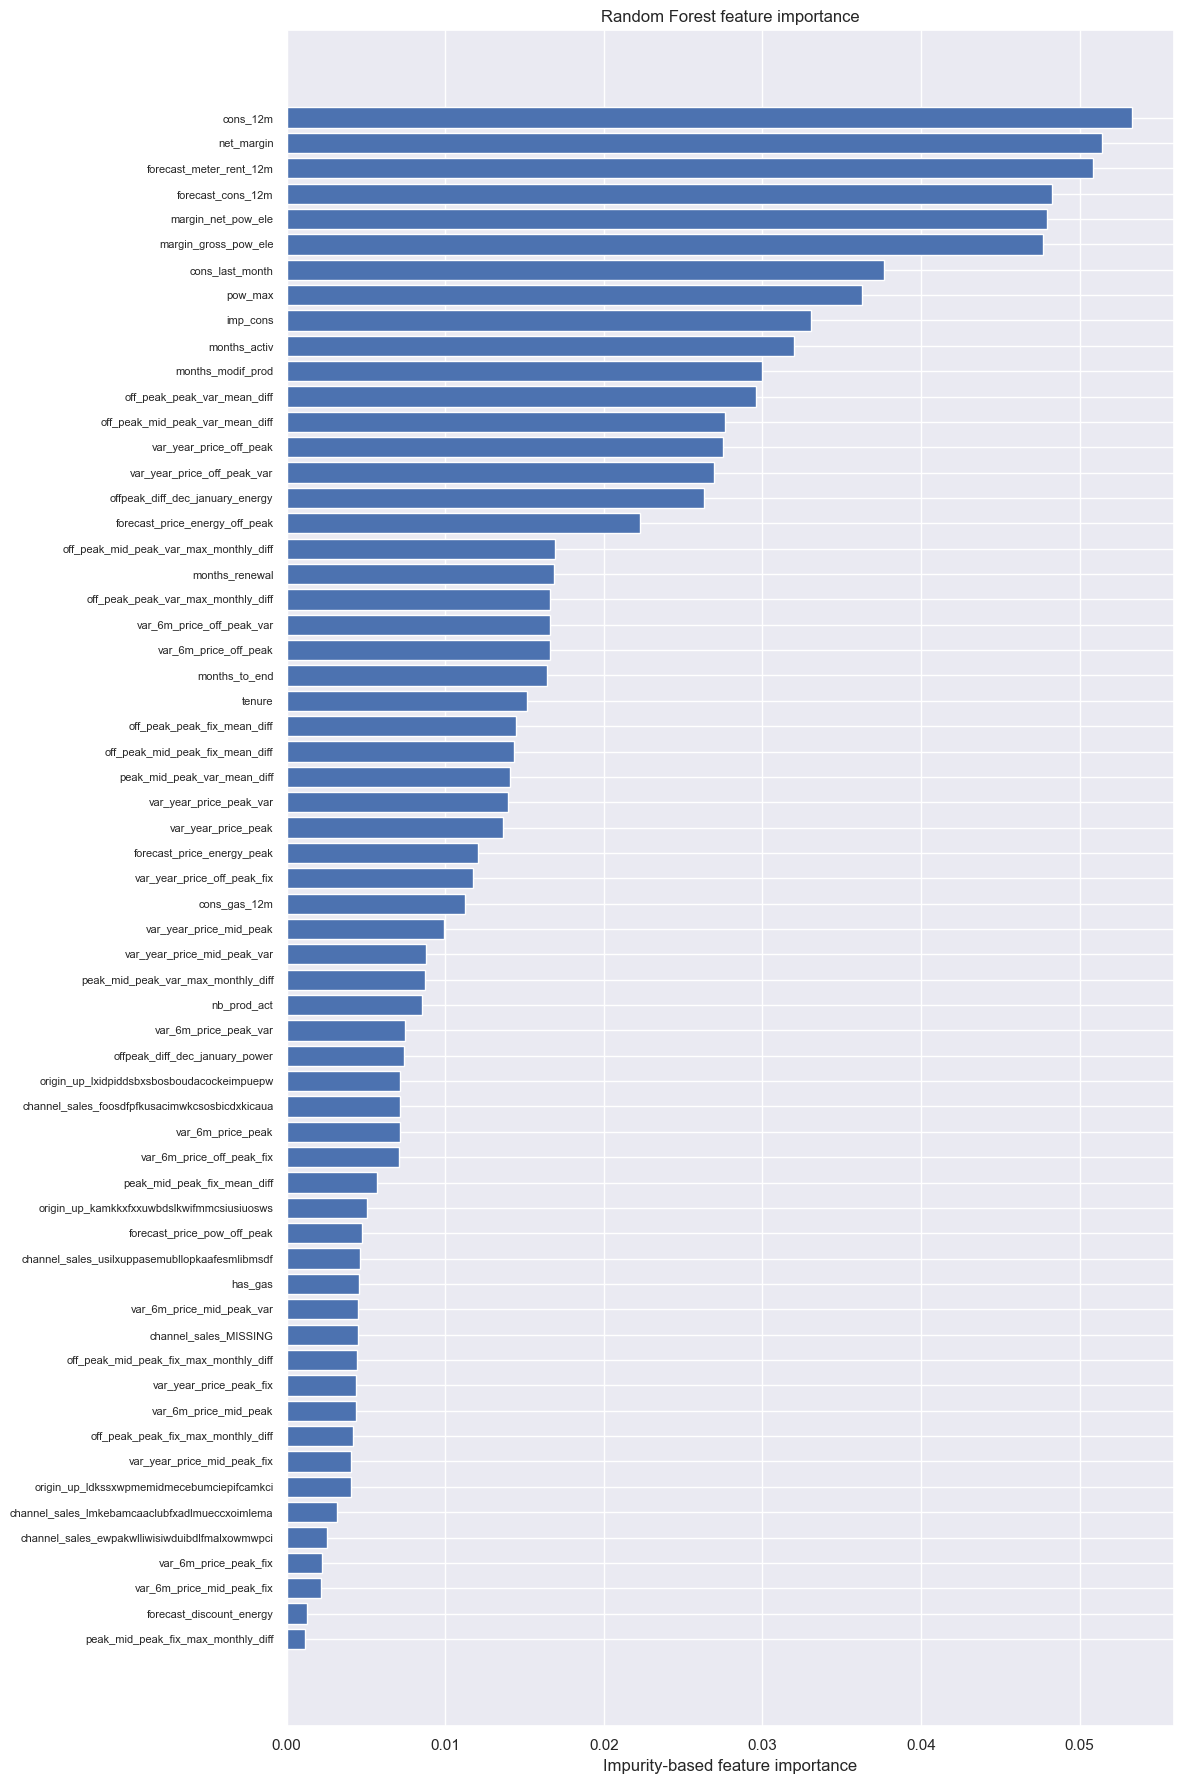

In [53]:
plt.figure(figsize=(12,18))
plt.barh(range(len(feature_importances)),feature_importances["importance"],align="center")
plt.yticks(range(len(feature_importances)),feature_importances["features"],fontsize=8)
plt.xlabel("Impurity-based feature importance")
plt.title("Random Forest feature importance")
plt.tight_layout()
plt.show()


In [54]:
feature_importances.sort_values("importance",ascending=False).head(15)[["features","importance"]]


                           features  importance
60                         cons_12m    0.053285
59                       net_margin    0.051387
58          forecast_meter_rent_12m    0.050827
57                forecast_cons_12m    0.048230
56               margin_net_pow_ele    0.047970
55             margin_gross_pow_ele    0.047674
54                  cons_last_month    0.037678
53                          pow_max    0.036262
52                         imp_cons    0.033044
51                     months_activ    0.031995
50                months_modif_prod    0.029972
49      off_peak_peak_var_mean_diff    0.029613
48  off_peak_mid_peak_var_mean_diff    0.027617
47          var_year_price_off_peak    0.027508
46      var_year_price_off_peak_var    0.026934

## Part 7: Prediction export and summary

Optionally export held-out predictions locally. Exports remain in the ignored `results` folder and are not uploaded to the repository.


In [55]:
prediction_output=X_test.reset_index(drop=True).copy()
prediction_output["predicted_churn"]=predictions
prediction_output["churn_probability"]=probabilities
if EXPORT_PREDICTIONS:
    output_dir=PROJECT_ROOT/"results"
    output_dir.mkdir(parents=True,exist_ok=True)
    prediction_output.to_csv(output_dir/"out_of_sample_data_with_predictions.csv",index=False)
    print("Saved a local prediction export in the ignored results folder.")
else:
    print("Prediction export is disabled; no customer-level output file has been written.")


Prediction export is disabled; no customer-level output file has been written.


### Interpretation and next steps

The notebook connects exploratory comparisons, the supplied pricing/contract features, a held-out split and Random Forest evaluation in one sequence. Retention recommendations should consider the observed recall/precision trade-off rather than accuracy alone. Threshold choice, class-imbalance handling and additional validation are possible future improvements, not completed experiments in this notebook.

Category-frequency screening and correlation diagnostics follow the supplied full-dataset preprocessing workflow. A further validation iteration could fit preprocessing decisions on the training subset only. Model rankings and price-related features provide predictive evidence; they do not establish that changing prices would cause retention improvements.

**Source attribution:** Task 2 was supplied as a revision based on answers; feature engineering and model training were adapted from the provided Task 3/4 BCG X / Forage model-answer notebooks. The merged workflow and current executed results should be understood in that guided simulation context.
